## Simple simulation without Airbrakes
To test the general assumptions, we will first do an analytical analysis to compare to a more vetted system like the openrocket simulation.

Before any CFD is done, an estimate for the $C_d$ of the nose cone assuming a tangent-ogive 5:1 shape with an OD of $140mm$ was asked from claude and shall later be revised. The estimate seems plausible at around $0.05$.

At motor burnout, which is when airbrake deployment will start, the vertical velocity is 129 m/s and the altitude around 250m (using openrocket model).

(The first simulation will use the following estimates by claude for the drag coefficients) [https://claude.ai/share/cfec519b-c237-4f9b-a31a-323d5c9f6205]

|Component	              |  Cd (frontal area)|
|------------|------|
|Nose (5:1 tangent ogive)|	0.05|
|Tube skin friction|	        0.13|
|Fins (friction, form, TE)|	0.05 to 0.06|
|Base|	                    0.07 to 0.12|
|Subtotal|	               0.30 to 0.36|

We will just assume constant airpressure, although the error sits at around 12% (0.889996 @ 1km) but then velocity is almost zero so drag is neglible anyways.
Gravity can definitely be assumed to be constant in our case.

In [1]:
import math
import numpy as np
import scipy.constants
import scipy.integrate as itg
import matplotlib.pylab as plt
import typing


# Model without airbrakes
t0 = 3 # s
rocket_OD = 0.124
start_height = 250 # m
start_velocity = 129 # m/s
C_d = 0.34
air_density = 1.225 # kg/m³
crosssectional_area = (math.pi * (rocket_OD/2)**2) # m²
rocket_burnout_mass = 15.59 # kg

surface_temp = 20 + 273.15 # Kelvin
surface_pressure = 101_325 # pascal


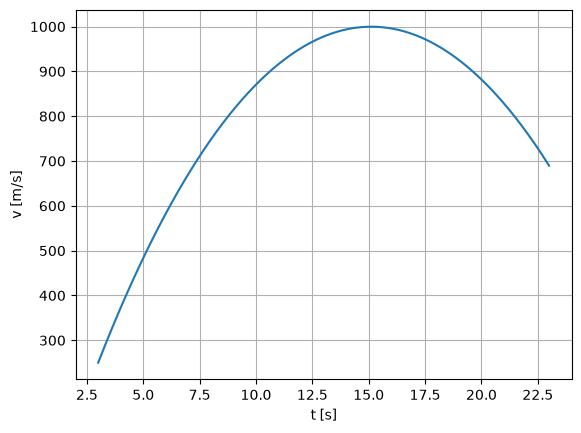

Apogee: 999.7190801050148
Max Velocity: 129.0


In [2]:

total_coeff = 0.5 * air_density * C_d * crosssectional_area 
def dynamic_system(t,x):
    dx_dt = x[1] # read as: x' = v = v
    F_d = total_coeff * (x[1]**2) # F_D = 1/2 p A C_d v²
    # drag_deceleration = F_d / rocket_burnout_mass # a = F/m
    dy_dt = -9.81 - (0.5*air_density * (x[1]**2) * C_d * crosssectional_area)/rocket_burnout_mass
    return [dx_dt, dy_dt]


# OpenRocket showed a flight time of 30s, so use 60s here with safety margin for bad sim
solver = itg.RK45(dynamic_system, t0, [start_height,start_velocity], 200, max_step=0.005)
soly = solver.y.reshape(1, 2)
solt = [t0]
# run the simulation for 2000 steps
for i in range(4000):
    if solver.status == "failed":
        print(f"Done after {i} iterations")
        break
    solver.step()
    solyn = solver.y.reshape(1, 2)
    soly = np.concatenate((soly, solyn))
    solt.append(solver.t)

plt.plot(solt,soly[:,0])
plt.xlabel("t [s]")
plt.ylabel("v [m/s]")
plt.grid(True)
plt.show()

print(f"Apogee: {max(soly[:,0])}")
print(f"Max Velocity: {max(soly[:,1])}")



## Analysis
With an apogee of $983m$ we are within 3% of the OpenRocket result which is a lot better than assumed.


## Adding the airbrakes
For now the airbrakes will act as a tuning point for the drag, as they can extend and therefore increase drag or fully move into the rockets body to get back to the baseline with an altitude of $983m$ as per our simulation.
We will treat the dynamic_system function like the flight controllers main loop and adjust the airbrake position on each step. We need to account for the fact, that they are still a mechanical component and can therefore not teleport to any position, but need time to move there.


### Warning
I am sceptical of how realistic this model is, as the extension of the airbrakes will get rid of the skin-friction of the rocket body (a certain distance below the airbrakes atleast). Presumably the pressure drag is much greater than the lost skin-friction but this assumption has to be validated.  

Servo used is the MG995R


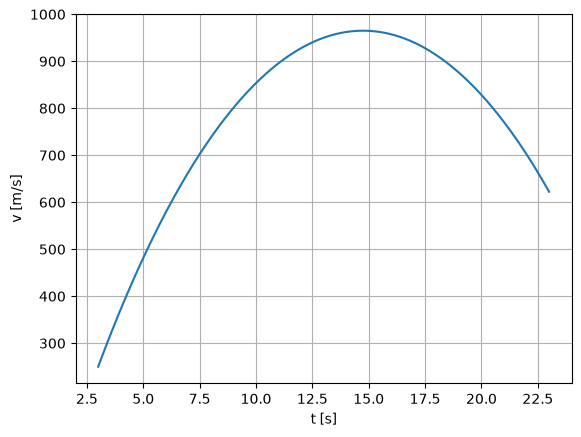

Apogee: 965.0902724694629
Max Velocity: 129.0


In [3]:

rect_flap_height = 72e-3 # m
rect_flap_width = 17.425e-3 #m

# Source: https://en.wikipedia.org/wiki/File:Hoerner_fluid_dynamic_drag_coefficients.svg
airbrake_drag_coefficient = 1.17

"""
 @brief Temperature as function of height.
 @param height Height above sea level in meters
 @return Temperature in Kelvin.
"""
def tempFromHeight(height: float) -> float:
    return -0.0065*height + surface_temp


"""
 @brief Air density from height
 @param height Height above sea level.
 @return Air density in kg/m³ 
"""
def airDensityFromHeight(height:float) -> float:
    air_pressure = surface_pressure * math.exp(-(1/8400) * height) # could linearize this
    R_spec = scipy.constants.gas_constant / 0.0289652 # second number is molar mass of dry air
    temp = tempFromHeight(height)

    return air_pressure / (R_spec * temp)

"""
 @brief     Converts extension to additional exposed surface area.
 @details   This is an approximation, assuming a linear behaviour and the flaps
            being rectangular.
 @param     extension Value from 0 to 1 that defines how far the airbrakes are extended
 @return    New area perpendicular to air stream in m²
"""
def calculateAirbrakeSurfaceAreaFromExtension(extension: float) -> float:
    assert 0 <= extension and extension <= 1, "Invalid extension provided"
    
    maxArea: float = 3 * rect_flap_height * rect_flap_width
    return extension * maxArea

"""
 @brief     Drag force due to airbrake extension
 @details   Assumes same air density as whole rocket.
 @return    Force in Newtons.
"""
def airbrakeAdditionalDragForce(airbrakeExtension:float, velocity: float, spec_airdensity: float) -> float:
    airbrakeSurfaceArea: float = calculateAirbrakeSurfaceAreaFromExtension(airbrakeExtension)
    
    force = 0.5 * spec_airdensity * airbrakeSurfaceArea * airbrake_drag_coefficient * (velocity ** 2)
    return force


# This is our control algorithm
def calculateAirbrakeExtension(t:float, xh:float,v:float) -> float:
    return .5

def dynamic_system(t,x):
    dx_dt = x[1] # read as: x' = v = v
    spec_air_density = airDensityFromHeight(x[0])
    F_d_body = 0.5 * spec_air_density * crosssectional_area * C_d * (x[1]**2) # F_D = 1/2 p A C_d v²
    airbrakeExtension = calculateAirbrakeExtension(t,x[0],x[1])
    airbrakeDragForce = airbrakeAdditionalDragForce(airbrakeExtension,x[1],spec_air_density)
    dy_dt = -9.81 - (F_d_body + airbrakeDragForce)/rocket_burnout_mass
    return [dx_dt, dy_dt]

# OpenRocket showed a flight time of 30s, so use 60s here with safety margin for bad sim
solver = itg.RK45(dynamic_system, t0, [start_height,start_velocity], 200, max_step=0.005)
soly = solver.y.reshape(1, 2)
solt = [t0]
# run the simulation for 2000 steps
for i in range(4000):
    if solver.status == "failed":
        print(f"Done after {i} iterations")
        break
    solver.step()
    solyn = solver.y.reshape(1, 2)
    soly = np.concatenate((soly, solyn))
    solt.append(solver.t)

plt.plot(solt,soly[:,0])
plt.xlabel("t [s]")
plt.ylabel("v [m/s]")
plt.grid(True)
plt.show()

print(f"Apogee: {max(soly[:,0])}")
print(f"Max Velocity: {max(soly[:,1])}")


### More precise model results
Adding air density, pressure and temperature that all depend on the height increase the estimated apogee by 5m (no airbrake).

More notably without any airbrakes we get a max height of 1005m while with full breaking force our apogee is 930m. Our target should therefore fall somewhere in this window, since otherwise the smartest control loop wouldn't be able to reach its target as we are lacking control authority. Another caveat to these simulations it that we are always assuming a 90° launch and aren't accounting for any effects due to the rocket spinning (caused by slightly missaligned fins). Therefore we cannot really be sure what the window possible window will be. For now we will continue with a targetApogee of $970m$ as a rough middle point between the two extremes. 

## Goal defintion and Adding realism
Since in the above simulation we can easily reach our goal by adjusting the extension of the airbrakes throughout the entire flight (to something around 0.5) we must introduce noise and imprecise values to get rid of this determinism. The most important parameters we will tweak are the start velocity after burnout, the C_d of the body and the C_d of the airbrakes.

The goal of our control algorithm is having zero vertical velocity at the target apogee. Physically we only have control over the vertical acceleration. We could have a short sequence that fully extends the airbrakes to determine drag coefficients and then fit a model to determine the constant deceleration we would need.

We can also add a bit of sensor noise in the next iteration.

### Control Algo
The first approach consists of two phases. At first we only observe and try to determine the body drag force from that (maybe the first second). After that we run a quick simulation *each iteration* and adjust the airbrake extension such that the apogee results in our target. Maybe use bayesion statestics here to constantly update our model of the world (tuning airbrake/body Cd). 

Cd:  0.3290498483404258


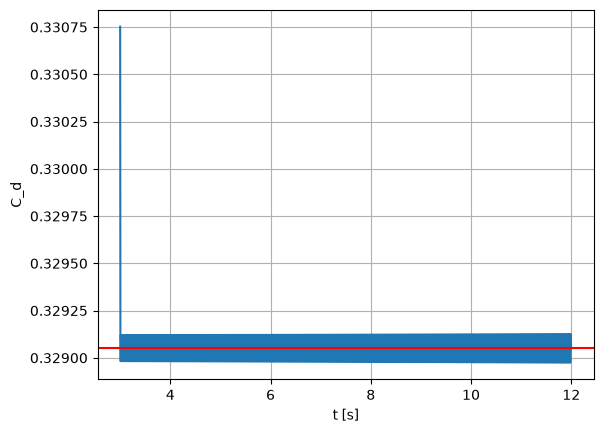

Apogee: 962.197592417823
Max Velocity: 129.0


In [4]:
import random

random.seed(0x421)
airbrake_cd = random.gauss(1.17,0.1)
C_d = random.gauss(0.34,0.01)
burnout_velocity = random.gauss(129, 4)

print("Cd: ", C_d)

target_apogee = 970 # m (a bit higher, since we lose the first second of airbrake extension)

# Tuning points
phase_two_begin = 4.5 # when t >= 4, transition to phase two

vel_data = []
vel_data_ts = []

cd_estimates = []
avg_estimates = []

controller_body_cd_avg = -1

"""
 @brief Calculates airbrake extension to reach target apogee.
"""
def calculateAirbrakeExtension(t, h, v) -> float:
    global controller_body_cd_avg
    if t < phase_two_begin:
        # record data
        vel_data.append(v)
        vel_data_ts.append(t)

        #if more than three data points, start estimation
        n = len(vel_data)
        if n >= 3:
            # get central derivate
            a = ((vel_data[n-1] - vel_data[n-3]) / (vel_data_ts[n-1] - vel_data_ts[n-3]) )
            v = vel_data[n-2]

            # Since cross-sectinal area is also not precise, we can later merge both constants into one
            # that will be estimated.
            spec_ad = airDensityFromHeight(h)
            k = 0.5 * spec_ad * crosssectional_area
            cd_estimate = -((a+9.81)*rocket_burnout_mass) / (k*v**2)
            cd_estimates.append(cd_estimate)
            
            
        return 0.0
    else:
        # average always converged correctly in sim
        if controller_body_cd_avg == -1:
            controller_body_cd_avg = np.average(cd_estimates)
        
        

        return 1.0

solver = itg.RK45(dynamic_system, t0, [start_height,start_velocity], 200, max_step=0.005)
soly = solver.y.reshape(1, 2)
solt = [t0]
# run the simulation for 2000 steps
for i in range(4000):
    if solver.status == "failed":
        print(f"Done after {i} iterations")
        break
    solver.step()
    solyn = solver.y.reshape(1, 2)
    soly = np.concatenate((soly, solyn))
    solt.append(solver.t)

plt.plot(solt[0:len(cd_estimates)],cd_estimates)
plt.axhline(y=C_d,color="r",linestyle="-")
plt.xlabel("t [s]")
plt.ylabel("C_d")
plt.grid(True)
plt.show()

print(f"Apogee: {max(soly[:,0])}")
print(f"Max Velocity: {max(soly[:,1])}")
